# Model Metrics

## Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.metrics import precision_score, recall_score, make_scorer, fbeta_score, classification_report

## Load dataset

In [2]:
train_path = "../storage/datasets/dataset_train_2025-04-29-21-13-29.csv"
test_path = "../storage/datasets/dataset_test_2025-04-29-21-13-29.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Training set shape:", train_df.shape)
print("Testing set shape:", test_df.shape)
print("Number of unique customers in Train:", train_df['cc_num'].nunique())
print("Number of unique customers in Test:", test_df['cc_num'].nunique())

Training set shape: (26982, 15)
Testing set shape: (1350, 15)
Number of unique customers in Train: 600
Number of unique customers in Test: 150


## Check for Users

Here we check for the traing and testing set if they have district users.

In [3]:
train_customers = set(train_df['cc_num'].unique())
test_customers = set(test_df['cc_num'].unique())

common_customers = train_customers.intersection(test_customers)

if common_customers:
    print("There are common customers in both training and testing sets:", common_customers)
else:
    print("No common customers: the training and testing sets are fully disjoint by customer.")

No common customers: the training and testing sets are fully disjoint by customer.


In [4]:
train_df.head()

,cc_num,is_fraud,month_sin,month_cos,log_time_diff,amt_zscore,time_segment_daytime,time_segment_late_night,day_of_week_Friday,day_of_week_Monday,day_of_week_Saturday,day_of_week_Sunday,day_of_week_Thursday,day_of_week_Tuesday,day_of_week_Wednesday
0,344709867813900,1.0,5.000000e-01,8.660254e-01,2.603923,3.063744,False,True,False,False,False,False,False,True,False
1,377026671291680,0.0,1.224647e-16,-1.000000e+00,6.733461,-0.341908,True,False,False,False,False,False,False,True,False
2,6011104316292105,0.0,1.000000e+00,6.123234e-17,5.643325,0.110487,True,False,False,False,False,True,False,False,False
3,4587657402165341815,0.0,5.000000e-01,8.660254e-01,3.766612,0.251369,True,False,False,False,False,True,False,False,False
4,4586810168620942,0.0,1.224647e-16,-1.000000e+00,4.780663,-0.535271,False,True,False,False,False,False,False,False,True


In [5]:
test_df.head()

,cc_num,is_fraud,month_sin,month_cos,log_time_diff,amt_zscore,time_segment_daytime,time_segment_late_night,day_of_week_Friday,day_of_week_Monday,day_of_week_Saturday,day_of_week_Sunday,day_of_week_Thursday,day_of_week_Tuesday,day_of_week_Wednesday
0,345060451158891,0.0,-0.866025,5.000000e-01,5.478693,-0.303266,True,False,False,False,False,False,False,True,False
1,3546897637165774,0.0,-1.000000,-1.836970e-16,6.002981,-0.923866,True,False,True,False,False,False,False,False,False
2,3572976568630035,0.0,-0.500000,8.660254e-01,8.502279,-0.059034,True,False,False,False,False,False,True,False,False
3,38588538868506,0.0,-0.866025,5.000000e-01,6.592359,0.448551,True,False,False,False,False,False,True,False,False
4,38588538868506,0.0,-0.500000,8.660254e-01,5.833836,-0.316161,True,False,False,False,False,True,False,False,False


## Prepare Training and Testing sets

Here we prepare the training and testing set for the models. Separate the features and Target. We also remove the customer number because it is unnecessary for training.

In [6]:
y_train = train_df['is_fraud']
X_train = train_df.drop(columns=['is_fraud'])
y_test = test_df['is_fraud']
X_test = test_df.drop(columns=['is_fraud'])

In [7]:
X_train = X_train.drop(columns=['cc_num'], errors='ignore')
X_test = X_test.drop(columns=['cc_num'], errors='ignore')

## Model Testing

Here we train and test each model. We use precision and recall for our metrics.

### Random Forrest

In [8]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_precision = precision_score(y_test, rf_pred, pos_label=1)
rf_recall = recall_score(y_test, rf_pred, pos_label=1)

print("Random Forrest Results:")
print(f"Test Precision for Fraud: {rf_precision:.4f}")
print(f"Test Recall for Fraud: {rf_recall:.4f}")

Random Forrest Results:
Test Precision for Fraud: 0.9040
Test Recall for Fraud: 0.7956


### Neural Network

In [9]:
nn_model = MLPClassifier(hidden_layer_sizes=(50,), max_iter=300, random_state=42)
nn_model.fit(X_train, y_train)

nn_pred = nn_model.predict(X_test)

nn_precision = precision_score(y_test,nn_pred, pos_label=1)
nn_recall = recall_score(y_test,nn_pred, pos_label=1)

print("Neural Network Results:")
print(f"Test Precision for Fraud: {nn_precision:.4f}")
print(f"Test Recall for Fraud: {nn_recall:.4f}")

Neural Network Results:
Test Precision for Fraud: 0.9351
Test Recall for Fraud: 0.7689


### Support Vector Machine

In [10]:
svm_model = SVC(kernel='rbf', probability=True, random_state=42)
svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)

svm_precision = precision_score(y_test, svm_pred, pos_label=1)
svm_recall = recall_score(y_test, svm_pred, pos_label=1)

print("Support Vector Machine Results:")
print(f"Test Precision for Fraud: {svm_precision:.4f}")
print(f"Test Recall for Fraud: {svm_recall:.4f}")

Support Vector Machine Results:
Test Precision for Fraud: 0.9278
Test Recall for Fraud: 0.7422


### Plot Results

Here e plot the results of each model for better visualization.

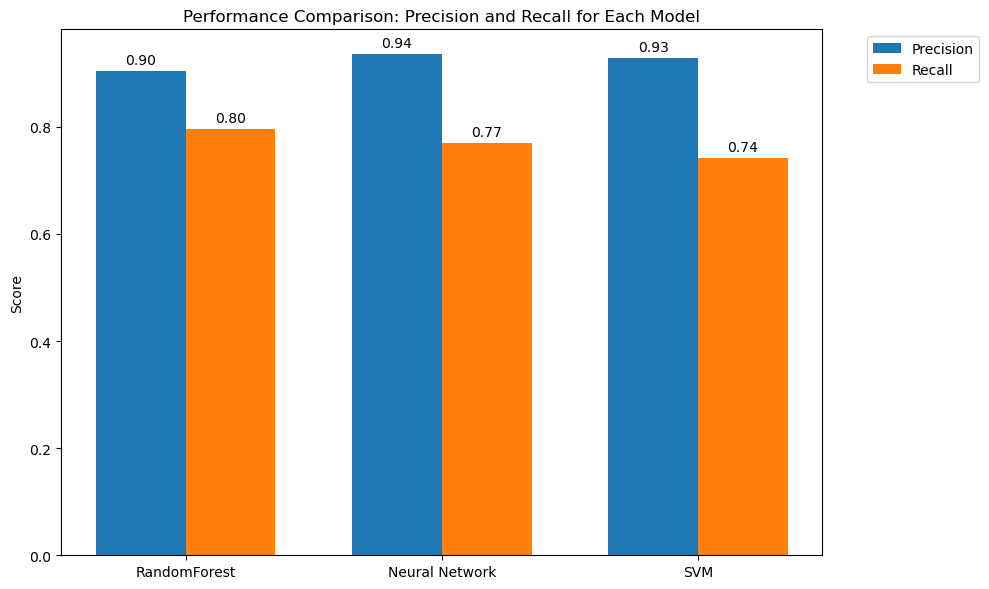

In [11]:
models = ['RandomForest', 'Neural Network', 'SVM']
precisions = [rf_precision, nn_precision, svm_precision]
recalls = [rf_recall, nn_recall, svm_recall]

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}', xy=(rect.get_x() + rect.get_width() / 2, height), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom')

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, precisions, width, label='Precision')
rects2 = ax.bar(x + width/2, recalls, width, label='Recall')

ax.set_ylabel('Score')
ax.set_title('Performance Comparison: Precision and Recall for Each Model')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

autolabel(rects1)
autolabel(rects2)

fig.tight_layout()
plt.show()

## Cross-Validation

We evaluated our models using a 10-k cross-validation.

In [12]:
models = [("Random Forrest", rf_model), ("Neural Network", nn_model), ("Support Vector Machine", svm_model)]

groups = train_df['cc_num']

scoring = {
    "precision": make_scorer(precision_score, pos_label=1),
    "recall": make_scorer(recall_score, pos_label=1)
}
gkf = GroupKFold(n_splits=5)

In [13]:
model_names = []
cv_precisions = []
cv_recalls = []

for name, model in models:
    print(f"Results for {name}:")

    cv_results = cross_validate(model, X_train, y_train, cv=gkf, groups=groups, scoring=scoring)
    mean_precision = np.mean(cv_results["test_precision"])
    mean_recall = np.mean(cv_results["test_recall"])

    model_names.append(name)
    cv_precisions.append(mean_precision)
    cv_recalls.append(mean_recall)

    print(f"{name} Cross-Validation Mean Precision: {mean_precision:.4f}")
    print(f"{name} Cross-Validation Mean Recall: {mean_recall:.4f}")
    print("\n" + "="*50 + "\n")

Results for Random Forrest:
Random Forrest Cross-Validation Mean Precision: 0.9007
Random Forrest Cross-Validation Mean Recall: 0.8042


Results for Neural Network:
Neural Network Cross-Validation Mean Precision: 0.9086
Neural Network Cross-Validation Mean Recall: 0.8016


Results for Support Vector Machine:
Support Vector Machine Cross-Validation Mean Precision: 0.9374
Support Vector Machine Cross-Validation Mean Recall: 0.7744




### Cross-Validation Plot Results

Here we use bar plots to see the preformance of each model using cross-validation.

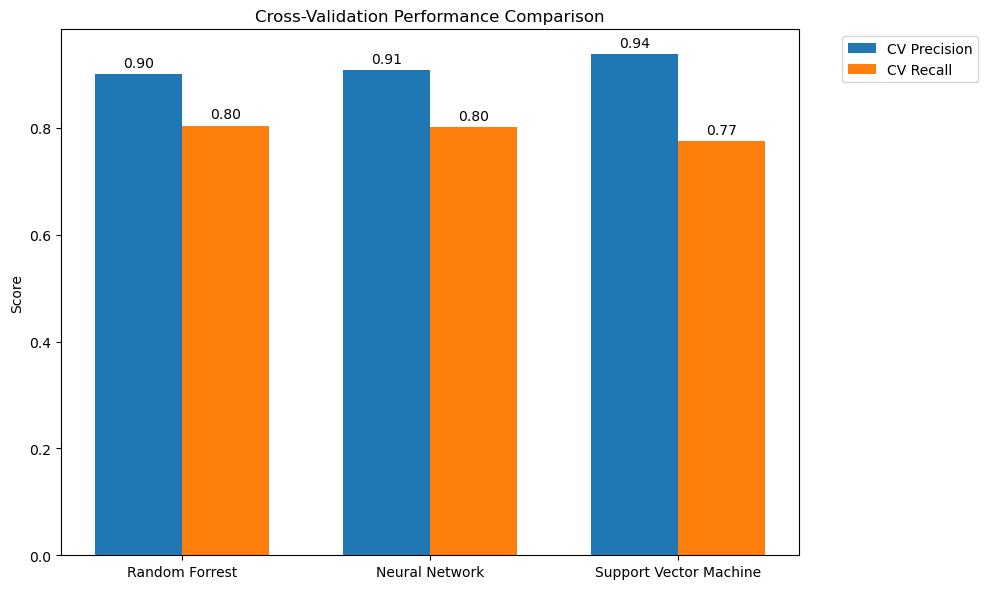

In [14]:
x = np.arange(len(model_names))  # X-axis locations for models
width = 0.35  # Width of the bars

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, cv_precisions, width, label='CV Precision')
rects2 = ax.bar(x + width/2, cv_recalls, width, label='CV Recall')

# Add labels, title, and legend.
ax.set_ylabel("Score")
ax.set_title("Cross-Validation Performance Comparison")
ax.set_xticks(x)
ax.set_xticklabels(model_names)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()